In [2]:
import os, random, math, hashlib
from dataclasses import dataclass
from typing import List, Optional

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import duckdb

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer, AutoModel,
    RobertaForMaskedLM,
    DataCollatorForLanguageModeling,
    DataCollatorWithPadding,
    set_seed as hf_set_seed,
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

import matplotlib.pyplot as plt

# Optional RDKit
try:
    from rdkit import Chem
    HAS_RDKIT = True
except Exception:
    HAS_RDKIT = False
    print("RDKit not found — skipping SMILES validity checks.")

@dataclass
class CFG:
    label_cols: List[str] = None
    base_model_name: str = "seyonec/ChemBERTa-zinc-base-v1"

    max_length_smiles: int = 128
    max_length_blocks: int = 16

    # Domain-specific MLM pretraining
    do_pretrain: bool = True   # set False if you want to skip MLM
    mlm_probability: float = 0.15
    pretrain_epochs: int = 2
    pretrain_lr: float = 5e-5
    pretrain_batch_size: int = 64
    pretrain_output_dir: str = "./belkabert_pretrain"

    # Fine-tuning
    finetune_epochs_stage1: int = 3
    finetune_epochs_stage2: int = 3
    train_batch_size: int = 32
    valid_batch_size: int = 64
    lr_heads: float = 2e-3
    lr_encoder: float = 5e-5
    weight_decay: float = 1e-4

    # Splits
    valid_size: float = 0.15
    test_size: float = 0.15

    # DuckDB downsample size
    downsample_nonbinders_to: int = 100_000

    seed: int = 42
    num_workers: int = 0
    pin_memory: bool = True
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

CFG.label_cols = ["BRD4", "HSA", "sEH"]

print("Device:", CFG.device)
hf_set_seed(CFG.seed)
random.seed(CFG.seed); np.random.seed(CFG.seed); torch.manual_seed(CFG.seed)


d:\leash-BELKA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [5]:
# os.makedirs("./duck_tmp", exist_ok=True)
# out_path = "belka_agg_downsampled.parquet"

# con = duckdb.connect("belka_tmp.duckdb")
# con.execute("PRAGMA memory_limit='10GB'")
# con.execute("PRAGMA temp_directory='./duck_tmp'")

# BASE_N = CFG.downsample_nonbinders_to

# query = f"""
# WITH agg AS (
#     SELECT
#         molecule_smiles,
#         MAX(CASE WHEN protein_name='BRD4' THEN binds ELSE 0 END) AS BRD4,
#         MAX(CASE WHEN protein_name='HSA'  THEN binds ELSE 0 END) AS HSA,
#         MAX(CASE WHEN protein_name='sEH'  THEN binds ELSE 0 END) AS sEH,
#         ANY_VALUE(buildingblock1_smiles) AS buildingblock1_smiles,
#         ANY_VALUE(buildingblock2_smiles) AS buildingblock2_smiles,
#         ANY_VALUE(buildingblock3_smiles) AS buildingblock3_smiles
#     FROM parquet_scan('train.parquet')
#     GROUP BY molecule_smiles
# ),
# tagged AS (
#     SELECT *, (BRD4*4 + HSA*2 + sEH) AS pattern_code
#     FROM agg
# ),
# nb AS (
#     SELECT * FROM tagged
#     WHERE pattern_code = 0
#     ORDER BY random()
#     LIMIT {BASE_N}
# ),
# binders AS (
#     SELECT * FROM tagged
#     WHERE pattern_code <> 0
# )
# SELECT * FROM binders
# UNION ALL
# SELECT * FROM nb
# """

# con.execute(f"COPY ({query}) TO '{out_path}' (FORMAT PARQUET, COMPRESSION ZSTD);")
# con.close()

# print("Wrote:", out_path)


In [6]:
df_bal = pd.read_parquet("belka_agg_downsampled.parquet")
print("Balanced df shape:", df_bal.shape)
display(df_bal.head())

if HAS_RDKIT:
    def is_valid_smiles(s):
        try:
            return Chem.MolFromSmiles(str(s)) is not None
        except Exception:
            return False

    before = len(df_bal)
    df_bal = df_bal[df_bal["molecule_smiles"].apply(is_valid_smiles)].reset_index(drop=True)
    print(f"Filtered invalid SMILES: {before} -> {len(df_bal)}")
else:
    print("Skipping SMILES validity filter.")


Balanced df shape: (1609779, 8)


,molecule_smiles,BRD4,HSA,sEH,buildingblock1_smiles,buildingblock2_smiles,buildingblock3_smiles,pattern_code
0,C#CC[C@H](CC(=O)N[Dy])Nc1nc(NCC2(O)C3C4CC5C6C4...,0,0,1,C#CC[C@H](CC(=O)O)NC(=O)OCC1c2ccccc2-c2ccccc21,Nc1ccnc(-c2ccccc2)c1,Cl.NCC1(O)C2C3CC4C5C3CC2C5C41,1
1,C#CC[C@H](Nc1nc(NCC(CC(N)=O)OC)nc(Nc2ncnc3[nH]...,0,1,0,C#CC[C@H](NC(=O)OCC1c2ccccc2-c2ccccc21)C(=O)O,COC(CN)CC(N)=O.Cl,Nc1ncnc2[nH]cnc12,2
2,C#CC[C@H](Nc1nc(NCC(C)Sc2ccccc2)nc(Nc2ccc(OC)c...,1,0,0,C#CC[C@H](NC(=O)OCC1c2ccccc2-c2ccccc21)C(=O)O,COc1ccc(N)cc1OC,CC(CN)Sc1ccccc1,4
3,C#CC[C@H](Nc1nc(NCc2ccsc2Br)nc(Nc2ccc(OC)c(OC)...,1,0,0,C#CC[C@H](NC(=O)OCC1c2ccccc2-c2ccccc21)C(=O)O,COc1ccc(N)cc1OC,NCc1ccsc1Br,4
4,C#CC[C@H](Nc1nc(NCCCCOc2ccccc2OC)nc(NCc2nc3ccc...,1,0,0,C#CC[C@H](NC(=O)OCC1c2ccccc2-c2ccccc21)C(=O)O,COc1ccccc1OCCCCN,NCc1nc2ccccc2s1,4


Filtered invalid SMILES: 1609779 -> 1609779


In [7]:
for c in CFG.label_cols:
    df_bal[c] = df_bal[c].astype(int)

df_bal["pattern"] = list(zip(df_bal["BRD4"], df_bal["HSA"], df_bal["sEH"]))
print("Pattern counts:")
display(df_bal["pattern"].value_counts())

train_df, temp_df = train_test_split(
    df_bal,
    test_size=(CFG.valid_size + CFG.test_size),
    stratify=df_bal["pattern"],
    random_state=CFG.seed
)
rel_test = CFG.test_size / (CFG.valid_size + CFG.test_size + 1e-9)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=rel_test,
    stratify=temp_df["pattern"],
    random_state=CFG.seed
)

for name, part in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    print(name, part.shape)


Pattern counts:


pattern
(0, 0, 1)    644702
(1, 0, 0)    456070
(0, 1, 0)    328942
(0, 0, 0)    100000
(0, 1, 1)     79171
(1, 0, 1)       597
(1, 1, 0)       235
(1, 1, 1)        62
Name: count, dtype: int64

train (1126845, 9)
valid (241467, 9)
test (241467, 9)


In [8]:
def hash_block(smiles: str) -> str:
    return hashlib.sha1(smiles.encode()).hexdigest()[:6]

def make_block_hash_seq(row):
    a = hash_block(row["buildingblock1_smiles"])
    b = hash_block(row["buildingblock2_smiles"])
    c = hash_block(row["buildingblock3_smiles"])
    return f"[CORE] A_{a} B_{b} C_{c}"

for frame in [train_df, valid_df, test_df]:
    frame["block_text"] = frame.apply(make_block_hash_seq, axis=1)

display(train_df[["molecule_smiles","block_text","BRD4","HSA","sEH"]].head())


,molecule_smiles,block_text,BRD4,HSA,sEH
147027,CC(CNc1nc(Nc2ccc3c(c2)CNC3=O)nc(Nc2cccc(Cl)c2C...,[CORE] A_510a3c B_f64426 C_d03a55,1,0,0
732567,CCC1=NN(Cc2ccccc2C)C(=O)C1CCNc1nc(NCCNC(=O)c2c...,[CORE] A_3b20fa B_23caa0 C_73bd05,0,0,1
248865,CC(C)(CCC#N)CNc1nc(NCc2noc3ccc(F)cc23)nc(N[C@@...,[CORE] A_8ae24a B_b31b10 C_7cf0cc,0,0,1
1536090,Cc1cc(Nc2nc(Nc3ccc(-c4ccccc4)cn3)nc(NC(CC(=O)N...,[CORE] A_15cc54 B_a5cdc8 C_175705,0,0,0
761666,O=C(N[Dy])[C@H]1CC[C@H](CNc2nc(Nc3ccc4nccnc4c3...,[CORE] A_fdf752 B_517f36 C_7cc90e,0,0,1


In [9]:
# SMILES tokenizer
smiles_tokenizer = AutoTokenizer.from_pretrained(CFG.base_model_name)

# BLOCK tokenizer with hashed tokens
blocks_tokenizer = AutoTokenizer.from_pretrained(CFG.base_model_name)

block_tokens = set(["[CORE]"])
for txt in train_df["block_text"].tolist():
    for tok in txt.split():
        if tok.startswith(("A_","B_","C_")):
            block_tokens.add(tok)
block_tokens = sorted(list(block_tokens))

blocks_tokenizer.add_special_tokens({"additional_special_tokens": block_tokens})

print("SMILES vocab size:", len(smiles_tokenizer))
print("BLOCK vocab size:", len(blocks_tokenizer))
print("Example block tokens:", block_tokens[:10])


SMILES vocab size: 767
BLOCK vocab size: 2604
Example block tokens: ['A_0045a8', 'A_015930', 'A_018b3e', 'A_02f0b1', 'A_035f9a', 'A_05e04b', 'A_060171', 'A_070f8a', 'A_0754bb', 'A_07b23c']


In [10]:
class TextLabelDataset(Dataset):
    def __init__(self, frame, text_col, label_cols, tokenizer, max_length):
        self.df = frame.reset_index(drop=True)
        self.text_col = text_col
        self.label_cols = label_cols
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self): 
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text = str(row[self.text_col])
        labels = row[self.label_cols].astype(float).values

        enc = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length,
            padding=False
        )
        return {
            "input_ids": torch.tensor(enc["input_ids"], dtype=torch.long),
            "attention_mask": torch.tensor(enc["attention_mask"], dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.float),
        }

def make_loader(ds, batch_size, tokenizer, shuffle=False, pin_memory=True):
    collator = DataCollatorWithPadding(tokenizer=tokenizer, padding=True, return_tensors="pt")
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=CFG.num_workers,
        pin_memory=pin_memory,
        collate_fn=collator
    )


In [11]:
class MultiLabelChemBERTaPlus(nn.Module):
    def __init__(self, model_name, freeze_encoder=True, disable_encoder_dropout=True, n_labels=3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        self.freeze_encoder = freeze_encoder

        if freeze_encoder:
            for p in self.encoder.parameters():
                p.requires_grad = False
            if disable_encoder_dropout:
                self.encoder.eval()

        H = self.encoder.config.hidden_size

        self.attn_weights = nn.Sequential(
            nn.Linear(H, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
        )
        self.classifier = nn.Sequential(
            nn.Linear(H * 2, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, n_labels),
        )

    def unfreeze_last(self, k=1):
        encoder_stack = None
        for attr in ["encoder","transformer","bert","roberta"]:
            if hasattr(self.encoder, attr):
                m = getattr(self.encoder, attr)
                if hasattr(m, "layer"):
                    encoder_stack = m.layer
                elif hasattr(m, "layers"):
                    encoder_stack = m.layers
                break
        if encoder_stack is None:
            raise AttributeError("Could not locate transformer layers.")
        for p in encoder_stack[-k:].parameters():
            p.requires_grad = True
        self.freeze_encoder = False

    def forward(self, input_ids, attention_mask):
        if self.freeze_encoder:
            with torch.no_grad():
                enc_out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        else:
            enc_out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)

        last_hidden = enc_out.last_hidden_state  # (B,T,H)
        mask = attention_mask                    # (B,T)

        denom = mask.sum(dim=1, keepdim=True).clamp(min=1e-9)
        mean_pool = (last_hidden * mask.unsqueeze(-1)).sum(dim=1) / denom

        attn_scores = self.attn_weights(last_hidden).squeeze(-1)
        attn_scores = attn_scores.masked_fill(mask == 0, -1e9)
        attn_w = torch.softmax(attn_scores, dim=1)
        attn_pool = (last_hidden * attn_w.unsqueeze(-1)).sum(dim=1)

        pooled = torch.cat([mean_pool, attn_pool], dim=1)
        logits = self.classifier(pooled)
        return logits


In [12]:
def get_pos_weights(frame, label_cols):
    weights = []
    for c in label_cols:
        pos = frame[c].sum()
        neg = len(frame) - pos
        weights.append(neg / max(pos, 1.0))
    return torch.tensor(weights, dtype=torch.float)

@torch.no_grad()
def evaluate(model, loader, criterion, device, threshold=0.5):
    model.eval()
    total_loss = 0.0
    all_logits, all_targets = [], []

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        targets = batch["labels"].to(device)

        logits = model(input_ids, attn)
        loss = criterion(logits, targets)
        total_loss += loss.item() * input_ids.size(0)

        all_logits.append(logits.detach().cpu())
        all_targets.append(targets.detach().cpu())

    all_logits = torch.cat(all_logits, dim=0).numpy()
    all_targets = torch.cat(all_targets, dim=0).numpy()

    probs = 1/(1+np.exp(-all_logits))
    preds = (probs >= threshold).astype(int)

    metrics = {}
    metrics["f1_macro"] = f1_score(all_targets, preds, average="macro", zero_division=0)

    aps = []
    for i, name in enumerate(CFG.label_cols):
        metrics[f"f1_{name}"] = f1_score(all_targets[:,i], preds[:,i], zero_division=0)
        y = all_targets[:,i]
        if len(np.unique(y)) > 1:
            metrics[f"roc_auc_{name}"] = roc_auc_score(y, probs[:,i])
            ap = average_precision_score(y, probs[:,i])
            metrics[f"ap_{name}"] = ap
            aps.append(ap)
        else:
            metrics[f"roc_auc_{name}"] = float("nan")
            metrics[f"ap_{name}"] = float("nan")

    metrics["mAP_macro"] = float(np.nanmean(aps)) if aps else float("nan")
    return total_loss/len(loader.dataset), metrics


In [13]:
class TextMLMDataset(Dataset):
    def __init__(self, texts, tokenizer, max_length):
        self.texts = list(texts)
        self.tok = tokenizer
        self.max_length = max_length
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        return self.tok(
            str(self.texts[idx]),
            truncation=True,
            max_length=self.max_length,
            padding=False
        )

def run_mlm_pretraining_pytorch(
    texts_train, texts_val,
    tokenizer, out_dir, max_length, tag,
    epochs, lr, batch_size, mlm_prob, device
):
    save_dir = os.path.join(out_dir, tag)
    os.makedirs(save_dir, exist_ok=True)

    model = RobertaForMaskedLM.from_pretrained(CFG.base_model_name)
    model.resize_token_embeddings(len(tokenizer))
    model.to(device)

    train_ds = TextMLMDataset(texts_train, tokenizer, max_length)
    val_ds   = TextMLMDataset(texts_val, tokenizer, max_length)

    collator = DataCollatorForLanguageModeling(
        tokenizer=tokenizer, mlm=True, mlm_probability=mlm_prob
    )

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, collate_fn=collator)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, collate_fn=collator)

    optim = torch.optim.AdamW(model.parameters(), lr=lr)

    train_losses = []
    val_losses = []

    def eval_mlm():
        model.eval()
        losses = []
        with torch.no_grad():
            for batch in val_loader:
                batch = {k:v.to(device) for k,v in batch.items()}
                losses.append(model(**batch).loss.item())
        return float(np.mean(losses)) if losses else 0.0

    # initial val loss (epoch 0)
    init_val = eval_mlm()
    val_losses.append(init_val)
    train_losses.append(np.nan)
    print(f"[{tag}] initial val MLM loss = {init_val:.4f}")

    best_val = init_val
    for ep in range(1, epochs+1):
        model.train()
        pbar = tqdm(train_loader, desc=f"[{tag}] MLM epoch {ep}/{epochs}")
        running = 0.0
        steps = 0
        for batch in pbar:
            batch = {k:v.to(device) for k,v in batch.items()}
            loss = model(**batch).loss

            optim.zero_grad(set_to_none=True)
            loss.backward()
            optim.step()

            running += loss.item()
            steps += 1
            pbar.set_postfix(loss=running/steps)

        train_losses.append(running/max(steps,1))
        val_loss = eval_mlm()
        val_losses.append(val_loss)
        print(f"[{tag}] ep {ep} val MLM loss = {val_loss:.4f}")

        if val_loss < best_val:
            best_val = val_loss
            model.save_pretrained(save_dir)
            tokenizer.save_pretrained(save_dir)

    print(f"[{tag}] best MLM checkpoint saved to {save_dir}")
    return save_dir, train_losses, val_losses


Some weights of the model checkpoint at seyonec/ChemBERTa-zinc-base-v1 were not used when initializing RobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


[smiles] initial val MLM loss = 2.2401


[smiles] MLM epoch 1/2: 100%|██████████| 17607/17607 [1:38:05<00:00,  2.99it/s, loss=0.0935]


[smiles] ep 1 val MLM loss = 0.0486


[smiles] MLM epoch 2/2: 100%|██████████| 17607/17607 [1:36:48<00:00,  3.03it/s, loss=0.0491]


...

[blocks] initial val MLM loss = 8.6151


[blocks] MLM epoch 1/2: 100%|██████████| 17607/17607 [36:46<00:00,  7.98it/s, loss=0.00141]


[blocks] ep 1 val MLM loss = 0.0000


[blocks] MLM epoch 2/2: 100%|██████████| 17607/17607 [37:00<00:00,  7.93it/s, loss=4.28e-10]


[blocks] ep 2 val MLM loss = 0.0000
[blocks] best MLM checkpoint saved to ./belkabert_pretrain\blocks


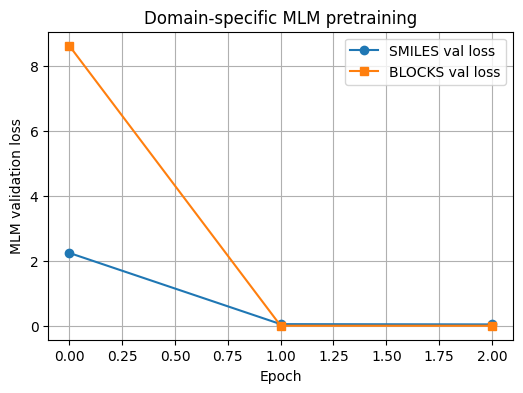

In [14]:
smiles_mlm_ckpt = None
blocks_mlm_ckpt = None
mlm_logs = {}

if CFG.do_pretrain:
    # SMILES
    smiles_mlm_ckpt, tr_sm, va_sm = run_mlm_pretraining_pytorch(
        train_df["molecule_smiles"].tolist(),
        valid_df["molecule_smiles"].tolist(),
        smiles_tokenizer,
        CFG.pretrain_output_dir,
        CFG.max_length_smiles,
        "smiles",
        CFG.pretrain_epochs,
        CFG.pretrain_lr,
        CFG.pretrain_batch_size,
        CFG.mlm_probability,
        CFG.device
    )
    mlm_logs["smiles"] = (tr_sm, va_sm)

    # BLOCKS
    blocks_mlm_ckpt, tr_bl, va_bl = run_mlm_pretraining_pytorch(
        train_df["block_text"].tolist(),
        valid_df["block_text"].tolist(),
        blocks_tokenizer,
        CFG.pretrain_output_dir,
        CFG.max_length_blocks,
        "blocks",
        CFG.pretrain_epochs,
        CFG.pretrain_lr,
        CFG.pretrain_batch_size,
        CFG.mlm_probability,
        CFG.device
    )
    mlm_logs["blocks"] = (tr_bl, va_bl)
else:
    print("Skipping MLM pretraining (CFG.do_pretrain=False)")

# ---- Plot MLM val losses ----
if CFG.do_pretrain:
    plt.figure(figsize=(6,4))
    epochs = list(range(len(mlm_logs["smiles"][1])))
    plt.plot(epochs, mlm_logs["smiles"][1], marker="o", label="SMILES val loss")
    plt.plot(epochs, mlm_logs["blocks"][1], marker="s", label="BLOCKS val loss")
    plt.xlabel("Epoch")
    plt.ylabel("MLM validation loss")
    plt.title("Domain-specific MLM pretraining")
    plt.legend()
    plt.grid(True)
    plt.show()


In [15]:
def finetune_one_representation(
    rep_name: str,
    text_col: str,
    tokenizer,
    max_length: int,
    base_ckpt: Optional[str]
):
    print(f"\n===== Fine-tuning {rep_name} =====")
    model_name = base_ckpt if base_ckpt is not None else CFG.base_model_name

    train_ds = TextLabelDataset(train_df, text_col, CFG.label_cols, tokenizer, max_length)
    valid_ds = TextLabelDataset(valid_df, text_col, CFG.label_cols, tokenizer, max_length)
    test_ds  = TextLabelDataset(test_df,  text_col, CFG.label_cols, tokenizer, max_length)

    pin_mem = CFG.pin_memory if "BLOCK" not in rep_name else False
    train_loader = make_loader(train_ds, CFG.train_batch_size, tokenizer, shuffle=True, pin_memory=pin_mem)
    valid_loader = make_loader(valid_ds, CFG.valid_batch_size, tokenizer, shuffle=False, pin_memory=pin_mem)
    test_loader  = make_loader(test_ds,  CFG.valid_batch_size, tokenizer, shuffle=False, pin_memory=pin_mem)

    model = MultiLabelChemBERTaPlus(
        model_name=model_name,
        freeze_encoder=True,
        disable_encoder_dropout=True,
        n_labels=len(CFG.label_cols)
    )
    model.encoder.resize_token_embeddings(len(tokenizer))
    device = CFG.device
    model = model.to(device)

    pos_weights = get_pos_weights(train_df, CFG.label_cols).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)

    # Stage 1: head only
    optim = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=CFG.lr_heads,
        weight_decay=CFG.weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=CFG.finetune_epochs_stage1)

    best_val = float("inf"); best_state = None
    for epoch in range(1, CFG.finetune_epochs_stage1+1):
        model.train()
        running = 0.0
        pbar = tqdm(train_loader, desc=f"{rep_name} Stage1 {epoch}/{CFG.finetune_epochs_stage1}")
        for batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attn = batch["attention_mask"].to(device)
            targets = batch["labels"].to(device)

            logits = model(input_ids, attn)
            loss = criterion(logits, targets)

            optim.zero_grad(set_to_none=True)
            loss.backward()
            optim.step()

            running += loss.item()*input_ids.size(0)
            pbar.set_postfix(loss=running/(pbar.n+1e-9))
        scheduler.step()

        val_loss, val_metrics = evaluate(model, valid_loader, criterion, device)
        print(f"{rep_name} Stage1 epoch {epoch}: val_loss={val_loss:.4f}, "
              f"f1_macro={val_metrics['f1_macro']:.4f}, mAP={val_metrics['mAP_macro']:.4f}")
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k:v.cpu().clone() for k,v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    # Stage 2: unfreeze last block
    model.unfreeze_last(k=1)
    model.encoder.train()

    head_params, enc_params = [], []
    for n,p in model.named_parameters():
        if p.requires_grad:
            (enc_params if n.startswith("encoder.") else head_params).append(p)

    optim = torch.optim.AdamW([
        {"params": head_params, "lr": CFG.lr_heads,   "weight_decay": CFG.weight_decay},
        {"params": enc_params,  "lr": CFG.lr_encoder, "weight_decay": CFG.weight_decay},
    ])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=CFG.finetune_epochs_stage2)

    best_val = float("inf"); best_state = None
    for epoch in range(1, CFG.finetune_epochs_stage2+1):
        model.train()
        running = 0.0
        pbar = tqdm(train_loader, desc=f"{rep_name} Stage2 {epoch}/{CFG.finetune_epochs_stage2}")
        for batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attn = batch["attention_mask"].to(device)
            targets = batch["labels"].to(device)

            logits = model(input_ids, attn)
            loss = criterion(logits, targets)

            optim.zero_grad(set_to_none=True)
            loss.backward()
            optim.step()

            running += loss.item()*input_ids.size(0)
            pbar.set_postfix(loss=running/(pbar.n+1e-9))
        scheduler.step()

        val_loss, val_metrics = evaluate(model, valid_loader, criterion, device)
        print(f"{rep_name} Stage2 epoch {epoch}: val_loss={val_loss:.4f}, "
              f"f1_macro={val_metrics['f1_macro']:.4f}, mAP={val_metrics['mAP_macro']:.4f}")
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k:v.cpu().clone() for k,v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    test_loss, test_metrics = evaluate(model, test_loader, criterion, device)
    print(f"{rep_name} TEST: loss={test_loss:.4f}, "
          f"f1_macro={test_metrics['f1_macro']:.4f}, mAP={test_metrics['mAP_macro']:.4f}")
    return model, test_metrics


In [16]:
results = {}

# 1) SMILES – base ChemBERTa
smiles_base_model, smiles_base_metrics = finetune_one_representation(
    rep_name="SMILES_base",
    text_col="molecule_smiles",
    tokenizer=smiles_tokenizer,
    max_length=CFG.max_length_smiles,
    base_ckpt=None
)
results["SMILES_base"] = smiles_base_metrics

# 2) SMILES – domain-pretrained (BELKA-BERT)
smiles_domain_model, smiles_domain_metrics = finetune_one_representation(
    rep_name="SMILES_domain",
    text_col="molecule_smiles",
    tokenizer=smiles_tokenizer,
    max_length=CFG.max_length_smiles,
    base_ckpt=smiles_mlm_ckpt if CFG.do_pretrain else None
)
results["SMILES_domain"] = smiles_domain_metrics

# 3) BLOCKS – domain-pretrained (ablation)
blocks_model, blocks_metrics = finetune_one_representation(
    rep_name="BLOCKS_domain",
    text_col="block_text",
    tokenizer=blocks_tokenizer,
    max_length=CFG.max_length_blocks,
    base_ckpt=blocks_mlm_ckpt if CFG.do_pretrain else None
)
results["BLOCKS_domain"] = blocks_metrics

# Show comparison table
def summarize(name, m):
    return {
        "model": name,
        "f1_macro": m["f1_macro"],
        "f1_BRD4": m["f1_BRD4"],
        "f1_HSA": m["f1_HSA"],
        "f1_sEH": m["f1_sEH"],
        "roc_auc_BRD4": m["roc_auc_BRD4"],
        "roc_auc_HSA": m["roc_auc_HSA"],
        "roc_auc_sEH": m["roc_auc_sEH"],
        "mAP_macro": m["mAP_macro"],
    }

bench = pd.DataFrame([summarize(k, v) for k, v in results.items()])
display(bench)



===== Fine-tuning SMILES_base =====


SMILES_base Stage1 1/3: 100%|██████████| 35214/35214 [43:10<00:00, 13.59it/s, loss=13]  


SMILES_base Stage1 epoch 1: val_loss=0.3478, f1_macro=0.8179, mAP=0.8982


SMILES_base Stage1 2/3: 100%|██████████| 35214/35214 [43:04<00:00, 13.62it/s, loss=11.8]  


SMILES_base Stage1 epoch 2: val_loss=0.3316, f1_macro=0.8338, mAP=0.9045


...

BLOCKS_domain Stage2 2/3: 100%|██████████| 35214/35214 [17:08<00:00, 34.24it/s, loss=29.8]


BLOCKS_domain Stage2 epoch 2: val_loss=0.9299, f1_macro=0.1474, mAP=0.3292


BLOCKS_domain Stage2 3/3: 100%|██████████| 35214/35214 [17:08<00:00, 34.24it/s, loss=29.8]


BLOCKS_domain Stage2 epoch 3: val_loss=0.9299, f1_macro=0.1474, mAP=0.3292
BLOCKS_domain TEST: loss=0.9299, f1_macro=0.1474, mAP=0.3292


,model,f1_macro,f1_BRD4,f1_HSA,f1_sEH,roc_auc_BRD4,roc_auc_HSA,roc_auc_sEH,mAP_macro
0,SMILES_base,0.873676,0.923379,0.792458,0.905191,0.992146,0.949974,0.979199,0.932387
1,SMILES_domain,0.885784,0.937057,0.807278,0.913016,0.994058,0.954607,0.982478,0.939119
2,BLOCKS_domain,0.147403,0.442209,0.000000,0.000000,0.500000,0.500000,0.500000,0.329218


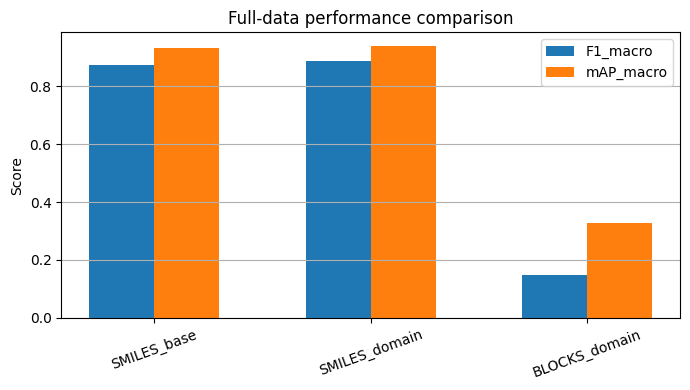

In [17]:
plt.figure(figsize=(7,4))
x = np.arange(len(results))
f1s = [results[k]["f1_macro"] for k in results]
maps = [results[k]["mAP_macro"] for k in results]

plt.bar(x - 0.15, f1s, width=0.3, label="F1_macro")
plt.bar(x + 0.15, maps, width=0.3, label="mAP_macro")
plt.xticks(x, list(results.keys()), rotation=20)
plt.ylabel("Score")
plt.title("Full-data performance comparison")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [18]:
def make_fewshot_train_df(k: int) -> pd.DataFrame:
    # sample up to k examples per pattern from train_df
    parts = []
    for pattern, group in train_df.groupby("pattern"):
        n = min(k, len(group))
        parts.append(group.sample(n=n, random_state=CFG.seed))
    fs = pd.concat(parts, axis=0).drop_duplicates().reset_index(drop=True)
    return fs

def finetune_on_custom_train(rep_name, text_col, tokenizer, max_length, base_ckpt, custom_train_df):
    # re-use valid_df/test_df, but use custom train_df
    tmp_train = custom_train_df.copy()

    train_ds = TextLabelDataset(tmp_train, text_col, CFG.label_cols, tokenizer, max_length)
    valid_ds = TextLabelDataset(valid_df, text_col, CFG.label_cols, tokenizer, max_length)
    test_ds  = TextLabelDataset(test_df,  text_col, CFG.label_cols, tokenizer, max_length)

    pin_mem = CFG.pin_memory
    train_loader = make_loader(train_ds, CFG.train_batch_size, tokenizer, shuffle=True, pin_memory=pin_mem)
    valid_loader = make_loader(valid_ds, CFG.valid_batch_size, tokenizer, shuffle=False, pin_memory=pin_mem)
    test_loader  = make_loader(test_ds,  CFG.valid_batch_size, tokenizer, shuffle=False, pin_memory=pin_mem)

    model_name = base_ckpt if base_ckpt is not None else CFG.base_model_name
    model = MultiLabelChemBERTaPlus(
        model_name=model_name,
        freeze_encoder=True,
        disable_encoder_dropout=True,
        n_labels=len(CFG.label_cols)
    )
    model.encoder.resize_token_embeddings(len(tokenizer))
    device = CFG.device
    model = model.to(device)

    pos_weights = get_pos_weights(tmp_train, CFG.label_cols).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)

    # shorter training for few-shot
    epochs1, epochs2 = 2, 2

    # Stage 1
    optim = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=CFG.lr_heads,
        weight_decay=CFG.weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=epochs1)

    best_val = float("inf"); best_state = None
    for epoch in range(1, epochs1+1):
        model.train()
        running = 0.0
        pbar = tqdm(train_loader, desc=f"{rep_name} FS Stage1 {epoch}/{epochs1}")
        for batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attn = batch["attention_mask"].to(device)
            targets = batch["labels"].to(device)

            logits = model(input_ids, attn)
            loss = criterion(logits, targets)

            optim.zero_grad(set_to_none=True)
            loss.backward()
            optim.step()

            running += loss.item()*input_ids.size(0)
            pbar.set_postfix(loss=running/(pbar.n+1e-9))
        scheduler.step()

        val_loss, _ = evaluate(model, valid_loader, criterion, device)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k:v.cpu().clone() for k,v in model.state_dict().items()}
    if best_state is not None:
        model.load_state_dict(best_state)

    # Stage 2
    model.unfreeze_last(k=1)
    model.encoder.train()

    head_params, enc_params = [], []
    for n,p in model.named_parameters():
        if p.requires_grad:
            (enc_params if n.startswith("encoder.") else head_params).append(p)

    optim = torch.optim.AdamW([
        {"params": head_params, "lr": CFG.lr_heads,   "weight_decay": CFG.weight_decay},
        {"params": enc_params,  "lr": CFG.lr_encoder, "weight_decay": CFG.weight_decay},
    ])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=epochs2)

    best_val = float("inf"); best_state = None
    for epoch in range(1, epochs2+1):
        model.train()
        running = 0.0
        pbar = tqdm(train_loader, desc=f"{rep_name} FS Stage2 {epoch}/{epochs2}")
        for batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attn = batch["attention_mask"].to(device)
            targets = batch["labels"].to(device)

            logits = model(input_ids, attn)
            loss = criterion(logits, targets)

            optim.zero_grad(set_to_none=True)
            loss.backward()
            optim.step()

            running += loss.item()*input_ids.size(0)
            pbar.set_postfix(loss=running/(pbar.n+1e-9))
        scheduler.step()

        val_loss, _ = evaluate(model, valid_loader, criterion, device)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k:v.cpu().clone() for k,v in model.state_dict().items()}
    if best_state is not None:
        model.load_state_dict(best_state)

    test_loss, test_metrics = evaluate(model, test_loader, criterion, device)
    return test_metrics



=== Few-shot k=5 per pattern ===
few-shot train size: (40, 10)


FS_SMILES_base_k5 FS Stage2 2/2: 100%|██████████| 2/2 [00:00<00:00, 18.52it/s, loss=2.78e+10]
Some weights of RobertaModel were not initialized from the model checkpoint at ./belkabert_pretrain\smiles and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
FS_SMILES_domain_k5 FS Stage2 2/2: 100%|██████████| 2/2 [00:00<00:00, 15.50it/s, loss=2.36e+10]



=== Few-shot k=10 per pattern ===
few-shot train size: (80, 10)


FS_SMILES_base_k10 FS Stage2 2/2: 100%|██████████| 3/3 [00:00<00:00, 12.24it/s, loss=49.4]    
Some weights of RobertaModel were not initialized from the model checkpoint at ./belkabert_pretrain\smiles and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
FS_SMILES_domain_k10 FS Stage2 2/2: 100%|██████████| 3/3 [00:00<00:00, 13.95it/s, loss=23]      



=== Few-shot k=20 per pattern ===
few-shot train size: (160, 10)


FS_SMILES_base_k20 FS Stage2 2/2: 100%|██████████| 5/5 [00:00<00:00, 10.44it/s, loss=26.7]    
Some weights of RobertaModel were not initialized from the model checkpoint at ./belkabert_pretrain\smiles and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
FS_SMILES_domain_k20 FS Stage2 2/2: 100%|██████████| 5/5 [00:00<00:00, 10.89it/s, loss=22.8]    



=== Few-shot k=50 per pattern ===
few-shot train size: (393, 10)


FS_SMILES_base_k50 FS Stage2 2/2: 100%|██████████| 13/13 [00:01<00:00, 11.98it/s, loss=19.1]   
Some weights of RobertaModel were not initialized from the model checkpoint at ./belkabert_pretrain\smiles and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
FS_SMILES_domain_k50 FS Stage2 2/2: 100%|██████████| 13/13 [00:01<00:00, 11.71it/s, loss=14.5]   



=== Few-shot k=100 per pattern ===
few-shot train size: (743, 10)


FS_SMILES_base_k100 FS Stage2 2/2: 100%|██████████| 24/24 [00:02<00:00, 10.97it/s, loss=18.9]   
Some weights of RobertaModel were not initialized from the model checkpoint at ./belkabert_pretrain\smiles and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
FS_SMILES_domain_k100 FS Stage2 2/2: 100%|██████████| 24/24 [00:02<00:00, 11.30it/s, loss=14.9]   


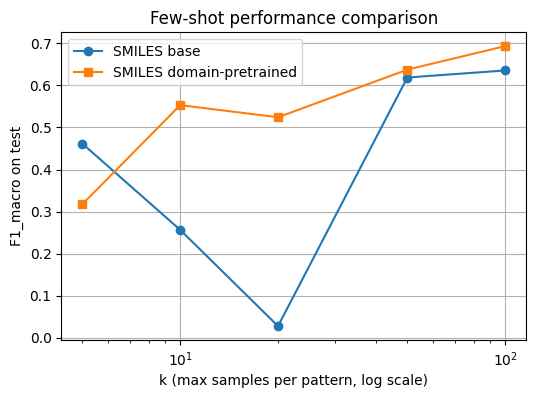

In [19]:
fewshot_ks = [5, 10, 20, 50, 100]
fs_results_base = []
fs_results_domain = []

for k in fewshot_ks:
    print(f"\n=== Few-shot k={k} per pattern ===")
    fs_train = make_fewshot_train_df(k)
    print("few-shot train size:", fs_train.shape)

    # Baseline ChemBERTa
    m_base = finetune_on_custom_train(
        rep_name=f"FS_SMILES_base_k{k}",
        text_col="molecule_smiles",
        tokenizer=smiles_tokenizer,
        max_length=CFG.max_length_smiles,
        base_ckpt=None,
        custom_train_df=fs_train
    )
    fs_results_base.append(m_base["f1_macro"])

    # Domain-pretrained ChemBERTa (BELKA-BERT)
    m_dom = finetune_on_custom_train(
        rep_name=f"FS_SMILES_domain_k{k}",
        text_col="molecule_smiles",
        tokenizer=smiles_tokenizer,
        max_length=CFG.max_length_smiles,
        base_ckpt=smiles_mlm_ckpt if CFG.do_pretrain else None,
        custom_train_df=fs_train
    )
    fs_results_domain.append(m_dom["f1_macro"])

# Plot few-shot F1 curves
plt.figure(figsize=(6,4))
plt.plot(fewshot_ks, fs_results_base, marker="o", label="SMILES base")
plt.plot(fewshot_ks, fs_results_domain, marker="s", label="SMILES domain-pretrained")
plt.xscale("log")
plt.xlabel("k (max samples per pattern, log scale)")
plt.ylabel("F1_macro on test")
plt.title("Few-shot performance comparison")
plt.legend()
plt.grid(True)
plt.show()


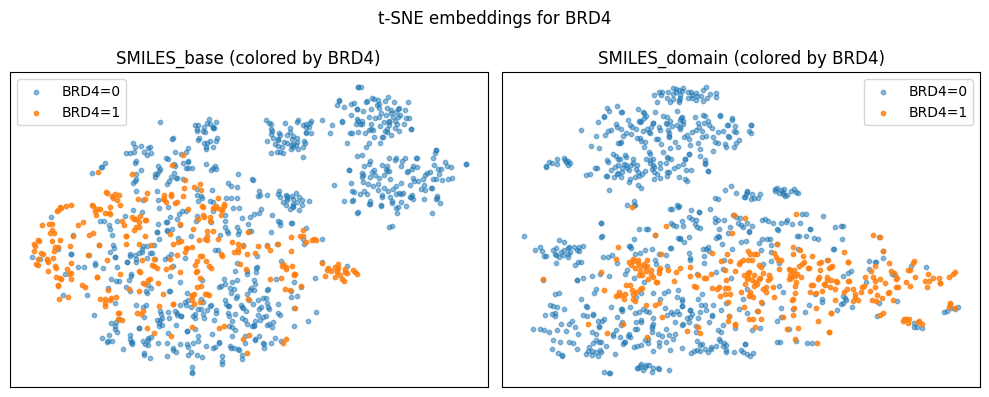

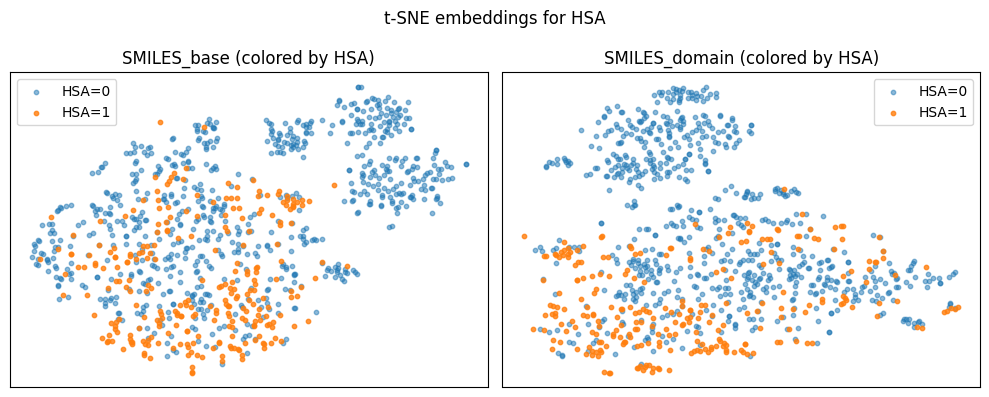

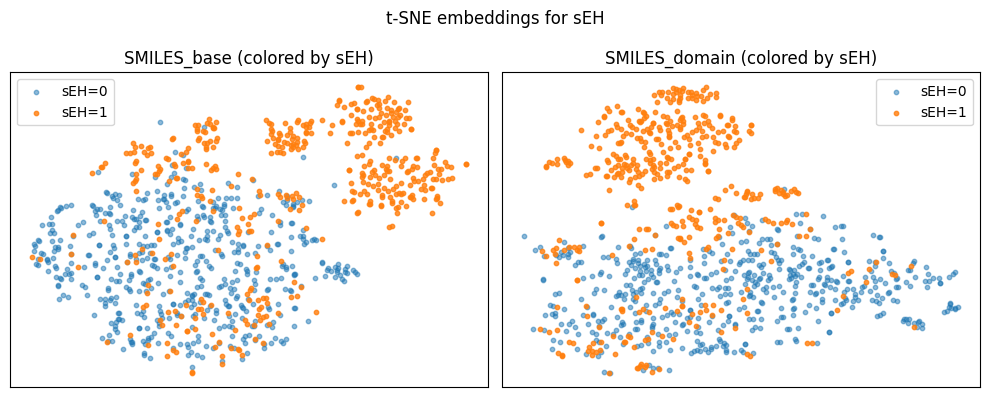

In [22]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

def get_encoder_pooled_embeddings(encoder, tokenizer, frame, text_col, max_length, n_samples=1000):
    # sample subset
    if len(frame) > n_samples:
        frame = frame.sample(n=n_samples, random_state=CFG.seed).reset_index(drop=True)

    device = CFG.device
    encoder = encoder.to(device)
    encoder.eval()

    ds = TextLabelDataset(frame, text_col, CFG.label_cols, tokenizer, max_length)
    loader = make_loader(ds, CFG.valid_batch_size, tokenizer, shuffle=False, pin_memory=False)

    all_embs = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attn = batch["attention_mask"].to(device)

            out = encoder(input_ids=input_ids, attention_mask=attn)
            last_hidden = out.last_hidden_state
            mask = attn

            denom = mask.sum(dim=1, keepdim=True).clamp(min=1e-9)
            mean_pool = (last_hidden * mask.unsqueeze(-1)).sum(dim=1) / denom

            all_embs.append(mean_pool.cpu().numpy())
            all_labels.append(batch["labels"].numpy())

    embs = np.concatenate(all_embs, axis=0)
    labels = np.concatenate(all_labels, axis=0)
    return embs, labels

# --- 1) Get embeddings for base vs domain SMILES encoders ---
emb_base, y_base = get_encoder_pooled_embeddings(
    smiles_base_model.encoder, smiles_tokenizer, test_df, "molecule_smiles", CFG.max_length_smiles, n_samples=1000
)
emb_dom,  y_dom  = get_encoder_pooled_embeddings(
    smiles_domain_model.encoder, smiles_tokenizer, test_df, "molecule_smiles", CFG.max_length_smiles, n_samples=1000
)

# We sampled with the same random_state inside the function, so y_base and y_dom correspond
# to the same molecules; we'll just use y_base for coloring.

# --- 2) Run t-SNE once per model ---
tsne_base = TSNE(n_components=2, random_state=CFG.seed, init="random", learning_rate="auto")
coords_base = tsne_base.fit_transform(emb_base)

tsne_dom = TSNE(n_components=2, random_state=CFG.seed, init="random", learning_rate="auto")
coords_dom = tsne_dom.fit_transform(emb_dom)

# --- 3) Helper: plot base vs domain side-by-side for a given target ---
def plot_tsne_for_target(target_name):
    idx = CFG.label_cols.index(target_name)
    labels = y_base[:, idx]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    # Base
    ax = axes[0]
    ax.scatter(coords_base[labels == 0, 0], coords_base[labels == 0, 1],
               s=10, alpha=0.5, label=f"{target_name}=0")
    ax.scatter(coords_base[labels == 1, 0], coords_base[labels == 1, 1],
               s=10, alpha=0.8, label=f"{target_name}=1")
    ax.set_title(f"SMILES_base (colored by {target_name})")
    ax.legend()
    ax.set_xticks([]); ax.set_yticks([])

    # Domain-pretrained
    ax = axes[1]
    ax.scatter(coords_dom[labels == 0, 0], coords_dom[labels == 0, 1],
               s=10, alpha=0.5, label=f"{target_name}=0")
    ax.scatter(coords_dom[labels == 1, 0], coords_dom[labels == 1, 1],
               s=10, alpha=0.8, label=f"{target_name}=1")
    ax.set_title(f"SMILES_domain (colored by {target_name})")
    ax.legend()
    ax.set_xticks([]); ax.set_yticks([])

    fig.suptitle(f"t-SNE embeddings for {target_name}")
    plt.tight_layout()
    plt.show()

# --- 4) Generate plots for BRD4, HSA, sEH ---
for target in ["BRD4", "HSA", "sEH"]:
    plot_tsne_for_target(target)


In [ ]:
def get_encoder_pooled_embeddings(encoder, tokenizer, frame, text_col, max_length, n_samples=1000):
    # sample subset
    if len(frame) > n_samples:
        frame = frame.sample(n=n_samples, random_state=CFG.seed).reset_index(drop=True)

    device = CFG.device
    encoder = encoder.to(device)
    encoder.eval()

    ds = TextLabelDataset(frame, text_col, CFG.label_cols, tokenizer, max_length)
    loader = make_loader(ds, CFG.valid_batch_size, tokenizer, shuffle=False, pin_memory=False)

    all_embs = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attn = batch["attention_mask"].to(device)

            out = encoder(input_ids=input_ids, attention_mask=attn)
            last_hidden = out.last_hidden_state
            mask = attn

            denom = mask.sum(dim=1, keepdim=True).clamp(min=1e-9)
            mean_pool = (last_hidden * mask.unsqueeze(-1)).sum(dim=1) / denom

            all_embs.append(mean_pool.cpu().numpy())
            all_labels.append(batch["labels"].numpy())

    embs = np.concatenate(all_embs, axis=0)
    labels = np.concatenate(all_labels, axis=0)
    return embs, labels

# Get embeddings for base vs domain SMILES encoders
emb_base, y_base = get_encoder_pooled_embeddings(
    smiles_base_model.encoder, smiles_tokenizer, test_df, "molecule_smiles", CFG.max_length_smiles, n_samples=1000
)
emb_dom,  y_dom  = get_encoder_pooled_embeddings(
    smiles_domain_model.encoder, smiles_tokenizer, test_df, "molecule_smiles", CFG.max_length_smiles, n_samples=1000
)

# t-SNE on base embeddings, color by BRD4 status
tsne = TSNE(n_components=2, random_state=CFG.seed, init="random", learning_rate="auto")
coords_base = tsne.fit_transform(emb_base)

brd4_labels = y_base[:, CFG.label_cols.index("BRD4")]

plt.figure(figsize=(5,5))
plt.scatter(coords_base[brd4_labels==0,0], coords_base[brd4_labels==0,1], s=10, alpha=0.5, label="BRD4=0")
plt.scatter(coords_base[brd4_labels==1,0], coords_base[brd4_labels==1,1], s=10, alpha=0.8, label="BRD4=1")
plt.title("t-SNE of SMILES_base embeddings (colored by BRD4)")
plt.legend()
plt.tight_layout()
plt.show()

# t-SNE on domain-pretrained embeddings, same labels
coords_dom = tsne.fit_transform(emb_dom)

plt.figure(figsize=(5,5))
plt.scatter(coords_dom[brd4_labels==0,0], coords_dom[brd4_labels==0,1], s=10, alpha=0.5, label="BRD4=0")
plt.scatter(coords_dom[brd4_labels==1,0], coords_dom[brd4_labels==1,1], s=10, alpha=0.8, label="BRD4=1")
plt.title("t-SNE of SMILES_domain embeddings (colored by BRD4)")
plt.legend()
plt.tight_layout()
plt.show()


C:\Users\NUFAYER\AppData\Local\Temp\ipykernel_22932\1034584489.py:15: RuntimeWarning: overflow encountered in exp
  probs = 1/(1+np.exp(-logits))
d:\leash-BELKA\.venv\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
d:\leash-BELKA\.venv\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


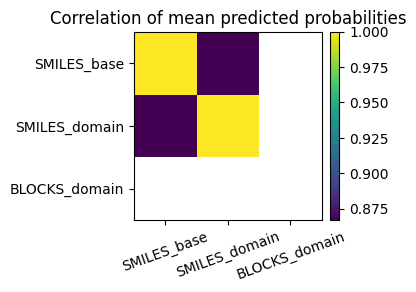

In [21]:
@torch.no_grad()
def get_probs(model, tokenizer, frame, text_col, max_length):
    ds = TextLabelDataset(frame, text_col, CFG.label_cols, tokenizer, max_length)
    loader = make_loader(ds, CFG.valid_batch_size, tokenizer, shuffle=False, pin_memory=False)
    device = CFG.device
    model = model.to(device)
    model.eval()
    all_logits = []
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        logits = model(input_ids, attn)
        all_logits.append(logits.cpu().numpy())
    logits = np.concatenate(all_logits, axis=0)
    probs = 1/(1+np.exp(-logits))
    return probs

# probs for test set for each model
p_base   = get_probs(smiles_base_model,   smiles_tokenizer, test_df, "molecule_smiles", CFG.max_length_smiles)
p_domain = get_probs(smiles_domain_model, smiles_tokenizer, test_df, "molecule_smiles", CFG.max_length_smiles)
p_blocks = get_probs(blocks_model,        blocks_tokenizer, test_df, "block_text",      CFG.max_length_blocks)

# flatten per model across targets
flat_base   = p_base.reshape(len(p_base), -1)
flat_domain = p_domain.reshape(len(p_domain), -1)
flat_blocks = p_blocks.reshape(len(p_blocks), -1)

# correlation matrix between model outputs
M = np.stack([
    flat_base.mean(axis=1),
    flat_domain.mean(axis=1),
    flat_blocks.mean(axis=1)
], axis=1)
corr = np.corrcoef(M.T)

plt.figure(figsize=(4,4))
im = plt.imshow(corr, interpolation="nearest")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(3), ["SMILES_base","SMILES_domain","BLOCKS_domain"], rotation=20)
plt.yticks(range(3), ["SMILES_base","SMILES_domain","BLOCKS_domain"])
plt.title("Correlation of mean predicted probabilities")
plt.tight_layout()
plt.show()


In [23]:
# ==== CELL 1: Map each building-block SMILES to an integer ID ====

all_blocks = pd.concat(
    [
        train_df["buildingblock1_smiles"],
        train_df["buildingblock2_smiles"],
        train_df["buildingblock3_smiles"],
        valid_df["buildingblock1_smiles"],
        valid_df["buildingblock2_smiles"],
        valid_df["buildingblock3_smiles"],
        test_df["buildingblock1_smiles"],
        test_df["buildingblock2_smiles"],
        test_df["buildingblock3_smiles"],
    ],
    axis=0,
).dropna().unique()

block2id = {sm: i for i, sm in enumerate(all_blocks)}
id2block = {i: sm for sm, i in block2id.items()}
N_BLOCKS = len(block2id)

print("Number of unique building blocks:", N_BLOCKS)

def encode_block_ids(frame):
    frame = frame.copy()
    frame["bb1_id"] = frame["buildingblock1_smiles"].map(block2id)
    frame["bb2_id"] = frame["buildingblock2_smiles"].map(block2id)
    frame["bb3_id"] = frame["buildingblock3_smiles"].map(block2id)
    return frame

train_df_blocks = encode_block_ids(train_df)
valid_df_blocks = encode_block_ids(valid_df)
test_df_blocks  = encode_block_ids(test_df)

# Long-format table for analysis (block-level SAR)
def make_long_blocks(frame, split_name):
    dfs = []
    for pos, col in enumerate(["bb1_id", "bb2_id", "bb3_id"], start=1):
        tmp = frame[[col] + CFG.label_cols].copy()
        tmp = tmp.rename(columns={col: "block_id"})
        tmp["position"] = pos
        tmp["split"] = split_name
        dfs.append(tmp)
    return pd.concat(dfs, axis=0).reset_index(drop=True)

blocks_long = pd.concat(
    [
        make_long_blocks(train_df_blocks, "train"),
        make_long_blocks(valid_df_blocks, "valid"),
        make_long_blocks(test_df_blocks,  "test"),
    ],
    axis=0,
).dropna(subset=["block_id"]).reset_index(drop=True)

print("blocks_long shape:", blocks_long.shape)
display(blocks_long.head())


Number of unique building blocks: 1145
blocks_long shape: (4829337, 6)


,block_id,BRD4,HSA,sEH,position,split
0,0,1,0,0,1,train
1,1,0,0,1,1,train
2,2,0,0,1,1,train
3,3,0,0,0,1,train
4,4,0,0,1,1,train


In [24]:
# ==== CELL 2: Block-level enrichment stats (interpretable SAR) ====

# overall frequency & binding rates per block (across positions/splits)
block_counts = (
    blocks_long.groupby("block_id")
    .size()
    .rename("count")
    .reset_index()
)

block_rates = (
    blocks_long.groupby("block_id")[CFG.label_cols]
    .mean()
    .reset_index()
)

block_stats = block_rates.merge(block_counts, on="block_id")
min_count = 20   # ignore super-rare blocks to reduce noise
block_stats_filt = block_stats[block_stats["count"] >= min_count].copy()

# attach SMILES strings
block_stats_filt["block_smiles"] = block_stats_filt["block_id"].map(id2block)

print("Block-level stats (filtered):")
display(block_stats_filt.head())

# ---- Show top enriched blocks for each target ----
TOPK = 10

for target in CFG.label_cols:
    print(f"\n=== Top {TOPK} blocks for {target} (by observed binding rate, count>={min_count}) ===")
    cols = ["block_smiles", "block_id", "count", target]
    disp = (
        block_stats_filt.sort_values(target, ascending=False)[cols]
        .head(TOPK)
        .reset_index(drop=True)
    )
    display(disp)


Block-level stats (filtered):


,block_id,BRD4,HSA,sEH,count,block_smiles
0,0,0.223458,0.530315,0.262113,3777,O=C(Nc1cccc(Cl)c1C(=O)O)OCC1c2ccccc2-c2ccccc21
1,1,0.098689,0.266985,0.582122,4195,O=C(O)C[C@H](Cc1ccc(Cl)c(Cl)c1)NC(=O)OCC1c2ccc...
2,2,0.259683,0.259196,0.442144,4105,N#Cc1cccc(C[C@H](CC(=O)O)NC(=O)OCC2c3ccccc3-c3...
3,3,0.492041,0.200143,0.272402,5591,O=C(O)CC(NC(=O)OCC1c2ccccc2-c2ccccc21)c1ccc(Br...
4,4,0.000334,0.000626,0.998025,164592,O=C(NC[C@H]1CC[C@H](C(=O)O)CC1)OCC1c2ccccc2-c2...



=== Top 10 blocks for BRD4 (by observed binding rate, count>=20) ===


,block_smiles,block_id,count,BRD4
0,Nc1cc(N2CCNCC2)ccc1[N+](=O)[O-],285,64599,0.989737
1,Cl.Cn1cc(N)ccc1=O,289,56440,0.971687
2,Nc1ccc2c(c1)CNC2=O,271,36032,0.966446
3,COc1ccc(N)cc1OC,281,24777,0.943456
4,CC(=O)SCCN.Cl,364,15235,0.914276
5,Cc1cc(N)ccc1O,352,9510,0.905258
6,CNC(=O)c1ccc(N)cc1F,318,13272,0.884870
7,Nc1cc(Cl)c(O)c(Cl)c1,519,19818,0.878393
8,NCc1ccc(CN2CCCC2=O)cc1,1010,13167,0.877345
9,CC(CCN)S(C)=O,300,8275,0.860302



=== Top 10 blocks for HSA (by observed binding rate, count>=20) ===


,block_smiles,block_id,count,HSA
0,Cl.NCc1cnc2n1CCOC2,286,29823,0.975019
1,Cl.NCc1nnc2ncccn12,420,18458,0.913208
2,Cl.Cl.NCC=Cc1cccnc1,376,21384,0.892583
3,Nc1cn[nH]c1,395,10195,0.837077
4,COc1cncc(N)n1,342,15049,0.812014
5,Cl.Cl.NC[C@@H]1CCO[C@H]1c1cn[nH]c1,427,5311,0.793824
6,Cl.Cl.Cn1cncc1CN,712,6801,0.780620
7,O=C(N[C@@H](Cc1cccnc1)C(=O)O)OCC1c2ccccc2-c2cc...,57,10321,0.762232
8,Nc1ccc(Cn2ccnc2)cc1,421,20381,0.753692
9,O=C(Nc1cnccc1C(=O)O)OCC1c2ccccc2-c2ccccc21,142,5164,0.746514



=== Top 10 blocks for sEH (by observed binding rate, count>=20) ===


,block_smiles,block_id,count,sEH
0,O=C(NCC1CCC(C(=O)O)CC1)OCC1c2ccccc2-c2ccccc21,13,260917,0.999475
1,O=C(NC[C@H]1CC[C@H](C(=O)O)CC1)OCC1c2ccccc2-c2...,4,164592,0.998025
2,CC(C)(CN)CCC#N,273,17041,0.977349
3,Cl.NCC1CCC2(CCC2)CO1,347,6415,0.949026
4,Cl.NCC12CC3CC(CC(C3)C1)C2,557,18857,0.946068
5,CC(CN)S(=O)(=O)N1CCN(c2ccccc2)CC1.Cl.Cl,544,10196,0.943703
6,Cl.NCC1(O)C2C3CC4C5C3CC2C5C41,452,15003,0.921416
7,Cl.NCCS(=O)(=O)c1ccc(Cl)cc1,526,5570,0.904309
8,NCCC1CSC1,302,29425,0.898556
9,NCC1CCC(C(F)F)CC1,498,8052,0.879285


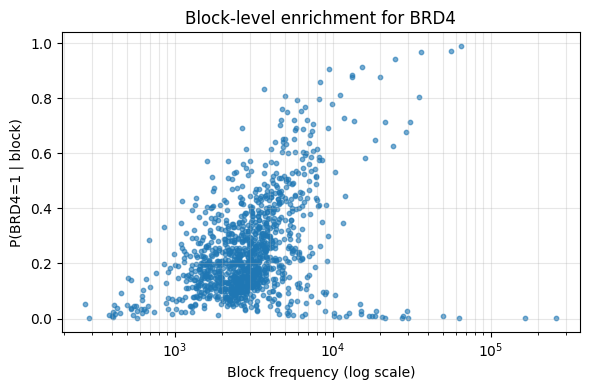

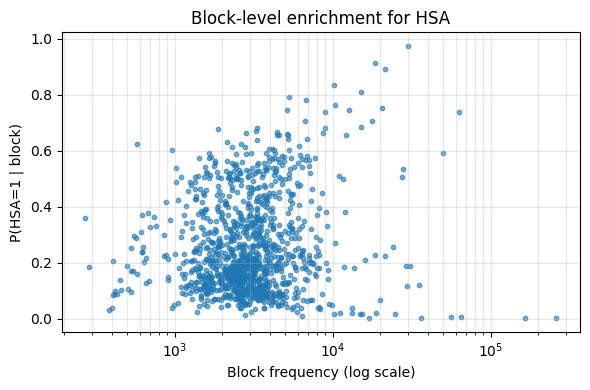

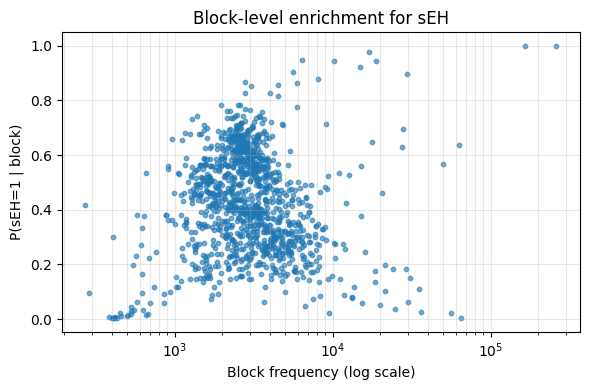

In [25]:
# ==== CELL 3: Visualize block statistics (scatter "heatmap") ====

import matplotlib.pyplot as plt

for target in CFG.label_cols:
    plt.figure(figsize=(6,4))
    x = block_stats_filt["count"]
    y = block_stats_filt[target]
    plt.scatter(x, y, s=10, alpha=0.6)
    plt.xscale("log")
    plt.xlabel("Block frequency (log scale)")
    plt.ylabel(f"P({target}=1 | block)")
    plt.title(f"Block-level enrichment for {target}")
    plt.grid(True, which="both", axis="both", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [26]:
# ==== CELL 4: Dataset + loader for SMILES + BLOCKS fusion model ====

class SmilesBlocksDataset(Dataset):
    def __init__(self, frame, label_cols, tokenizer, max_length):
        self.df = frame.reset_index(drop=True)
        self.label_cols = label_cols
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text = str(row["molecule_smiles"])
        labels = row[self.label_cols].astype(float).values

        enc = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length,
            padding=False,
        )

        bb_ids = np.array([row["bb1_id"], row["bb2_id"], row["bb3_id"]], dtype=np.int64)

        return {
            "input_ids": torch.tensor(enc["input_ids"], dtype=torch.long),
            "attention_mask": torch.tensor(enc["attention_mask"], dtype=torch.long),
            "bb_ids": torch.tensor(bb_ids, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.float),
        }

def make_fusion_loader(frame, tokenizer, max_length, batch_size, shuffle=False):
    ds = SmilesBlocksDataset(frame, CFG.label_cols, tokenizer, max_length)

    def collate_fn(batch):
        # separate text features for padding
        text_features = [
            {"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]}
            for b in batch
        ]
        padded = tokenizer.pad(
            text_features,
            padding=True,
            return_tensors="pt",
        )
        bb_ids = torch.stack([b["bb_ids"] for b in batch])
        labels = torch.stack([b["labels"] for b in batch])
        padded["bb_ids"] = bb_ids
        padded["labels"] = labels
        return padded

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=CFG.num_workers,
        pin_memory=CFG.pin_memory,
        collate_fn=collate_fn,
    )

# create block-augmented versions of splits
train_df_fusion = train_df_blocks.copy()
valid_df_fusion = valid_df_blocks.copy()
test_df_fusion  = test_df_blocks.copy()


In [ ]:
# ==== CELL 5: SMILES + BLOCKS fusion model ====

class SmilesBlocksFusionModel(nn.Module):
    def __init__(
        self,
        encoder_ckpt: str,
        n_blocks: int,
        block_dim: int = 64,
        n_labels: int = 3,
        freeze_encoder: bool = True,
    ):
        super().__init__()
        # SMILES encoder (ChemBERTa or your domain-pretrained checkpoint)
        self.encoder = AutoModel.from_pretrained(encoder_ckpt)
        H = self.encoder.config.hidden_size

        # optionally freeze encoder
        self.freeze_encoder = freeze_encoder
        if freeze_encoder:
            for p in self.encoder.parameters():
                p.requires_grad = False
            self.encoder.eval()

        # attention pooling for SMILES (same style as before)
        self.attn_weights = nn.Sequential(
            nn.Linear(H, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
        )

        # block embedding table
        self.block_embed = nn.Embedding(n_blocks, block_dim)

        # fusion classifier
        self.classifier = nn.Sequential(
            nn.Linear(H * 2 + block_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, n_labels),
        )

    def forward(self, input_ids, attention_mask, bb_ids):
        if self.freeze_encoder:
            with torch.no_grad():
                enc_out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        else:
            enc_out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)

        last_hidden = enc_out.last_hidden_state  # (B,T,H)
        mask = attention_mask                    # (B,T)

        # mean pooling
        denom = mask.sum(dim=1, keepdim=True).clamp(min=1e-9)
        mean_pool = (last_hidden * mask.unsqueeze(-1)).sum(dim=1) / denom

        # attention pooling
        attn_scores = self.attn_weights(last_hidden).squeeze(-1)
        attn_scores = attn_scores.masked_fill(mask == 0, -1e9)
        attn_w = torch.softmax(attn_scores, dim=1)
        attn_pool = (last_hidden * attn_w.unsqueeze(-1)).sum(dim=1)

        smiles_vec = torch.cat([mean_pool, attn_pool], dim=1)  # (B, 2H)

        # block embeddings: bb_ids shape (B,3)
        block_vecs = self.block_embed(bb_ids)          # (B,3,block_dim)
        block_vec = block_vecs.mean(dim=1)             # (B,block_dim)

        fused = torch.cat([smiles_vec, block_vec], dim=1)
        logits = self.classifier(fused)
        return logits


In [30]:
# ==== CELL 6: Train SMILES+BLOCKS fusion and compare to SMILES_domain ====

device = CFG.device

# use domain-pretrained SMILES checkpoint if available, otherwise base model
encoder_ckpt = smiles_mlm_ckpt if (CFG.do_pretrain and smiles_mlm_ckpt is not None) else CFG.base_model_name
print("Fusion model encoder checkpoint:", encoder_ckpt)

fusion_model = SmilesBlocksFusionModel(
    encoder_ckpt=encoder_ckpt,
    n_blocks=N_BLOCKS,
    block_dim=64,
    n_labels=len(CFG.label_cols),
    freeze_encoder=True,   # keep encoder frozen; train only blocks+head
).to(device)

# DataLoaders
fusion_train_loader = make_fusion_loader(
    train_df_fusion, smiles_tokenizer, CFG.max_length_smiles, CFG.train_batch_size, shuffle=True
)
fusion_valid_loader = make_fusion_loader(
    valid_df_fusion, smiles_tokenizer, CFG.max_length_smiles, CFG.valid_batch_size, shuffle=False
)
fusion_test_loader = make_fusion_loader(
    test_df_fusion,  smiles_tokenizer, CFG.max_length_smiles, CFG.valid_batch_size, shuffle=False
)

# Loss with pos_weight
pos_weights_fusion = get_pos_weights(train_df_fusion, CFG.label_cols).to(device)
criterion_fusion = nn.BCEWithLogitsLoss(pos_weight=pos_weights_fusion)

optim_fusion = torch.optim.AdamW(
    fusion_model.parameters(),
    lr=2e-3,
    weight_decay=CFG.weight_decay,
)
scheduler_fusion = torch.optim.lr_scheduler.CosineAnnealingLR(optim_fusion, T_max=5)

EPOCHS_FUSION = 5

best_val = float("inf"); best_state = None

for epoch in range(1, EPOCHS_FUSION + 1):
    fusion_model.train()
    running = 0.0
    pbar = tqdm(fusion_train_loader, desc=f"Fusion epoch {epoch}/{EPOCHS_FUSION}")
    for batch in pbar:
        input_ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        bb_ids = batch["bb_ids"].to(device)
        targets = batch["labels"].to(device)

        logits = fusion_model(input_ids, attn, bb_ids)
        loss = criterion_fusion(logits, targets)

        optim_fusion.zero_grad(set_to_none=True)
        loss.backward()
        optim_fusion.step()

        running += loss.item() * input_ids.size(0)
        pbar.set_postfix(loss=running / max(1, pbar.n))
    scheduler_fusion.step()

    # validation
    @torch.no_grad()
    def eval_fusion(model, loader, criterion):
        model.eval()
        tot_loss = 0.0
        all_logits, all_targets = [], []
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attn = batch["attention_mask"].to(device)
            bb_ids = batch["bb_ids"].to(device)
            targets = batch["labels"].to(device)

            logits = model(input_ids, attn, bb_ids)
            loss = criterion(logits, targets)
            tot_loss += loss.item() * input_ids.size(0)

            all_logits.append(logits.detach().cpu())
            all_targets.append(targets.detach().cpu())
        all_logits_ = torch.cat(all_logits, dim=0).numpy()
        all_targets_ = torch.cat(all_targets, dim=0).numpy()
        probs = 1.0 / (1.0 + np.exp(-all_logits_))
        preds = (probs >= 0.5).astype(int)

        metrics = {}
        metrics["f1_macro"] = f1_score(all_targets_, preds, average="macro", zero_division=0)
        aps = []
        for i, name in enumerate(CFG.label_cols):
            metrics[f"f1_{name}"] = f1_score(all_targets_[:, i], preds[:, i], zero_division=0)
            y = all_targets_[:, i]
            if len(np.unique(y)) > 1:
                metrics[f"roc_auc_{name}"] = roc_auc_score(y, probs[:, i])
                ap = average_precision_score(y, probs[:, i])
                metrics[f"ap_{name}"] = ap
                aps.append(ap)
            else:
                metrics[f"roc_auc_{name}"] = float("nan")
                metrics[f"ap_{name}"] = float("nan")
        metrics["mAP_macro"] = float(np.nanmean(aps)) if aps else float("nan")

        return tot_loss / len(loader.dataset), metrics

    val_loss, val_metrics = eval_fusion(fusion_model, fusion_valid_loader, criterion_fusion)
    print(f"Fusion epoch {epoch}: val_loss={val_loss:.4f}, "
          f"f1_macro={val_metrics['f1_macro']:.4f}, mAP={val_metrics['mAP_macro']:.4f}")

    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.cpu().clone() for k, v in fusion_model.state_dict().items()}

if best_state is not None:
    fusion_model.load_state_dict(best_state)

# test metrics
test_loss_fusion, test_metrics_fusion = eval_fusion(fusion_model, fusion_test_loader, criterion_fusion)
print("\nFUSION TEST:",
      f"loss={test_loss_fusion:.4f}, "
      f"f1_macro={test_metrics_fusion['f1_macro']:.4f}, "
      f"mAP={test_metrics_fusion['mAP_macro']:.4f}")


Some weights of RobertaModel were not initialized from the model checkpoint at ./belkabert_pretrain\smiles and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Fusion model encoder checkpoint: ./belkabert_pretrain\smiles


Fusion epoch 1/5: 100%|██████████| 35214/35214 [45:32<00:00, 12.89it/s, loss=8.6] 


Fusion epoch 1: val_loss=0.2422, f1_macro=0.8793, mAP=0.9352


Fusion epoch 2/5: 100%|██████████| 35214/35214 [46:15<00:00, 12.69it/s, loss=7.98]
C:\Users\NUFAYER\AppData\Local\Temp\ipykernel_22932\2717767739.py:84: RuntimeWarning: overflow encountered in exp
  probs = 1.0 / (1.0 + np.exp(-all_logits_))


...

Fusion epoch 4: val_loss=0.2251, f1_macro=0.8837, mAP=0.9420


Fusion epoch 5/5: 100%|██████████| 35214/35214 [45:45<00:00, 12.82it/s, loss=7.29]
C:\Users\NUFAYER\AppData\Local\Temp\ipykernel_22932\2717767739.py:84: RuntimeWarning: overflow encountered in exp
  probs = 1.0 / (1.0 + np.exp(-all_logits_))


Fusion epoch 5: val_loss=0.2214, f1_macro=0.8845, mAP=0.9432


C:\Users\NUFAYER\AppData\Local\Temp\ipykernel_22932\2717767739.py:84: RuntimeWarning: overflow encountered in exp
  probs = 1.0 / (1.0 + np.exp(-all_logits_))



FUSION TEST: loss=0.2203, f1_macro=0.8853, mAP=0.9432


,model,f1_macro,f1_BRD4,f1_HSA,f1_sEH,roc_auc_BRD4,roc_auc_HSA,roc_auc_sEH,mAP_macro
0,SMILES_base,0.873676,0.923379,0.792458,0.905191,0.992146,0.949974,0.979199,0.932387
1,SMILES_domain,0.885784,0.937057,0.807278,0.913016,0.994058,0.954607,0.982478,0.939119
2,BLOCKS_domain,0.147403,0.442209,0.000000,0.000000,0.500000,0.500000,0.500000,0.329218
3,SMILES+BLOCKS_fusion,0.885253,0.938896,0.800760,0.916104,0.994629,0.957521,0.984101,0.943152


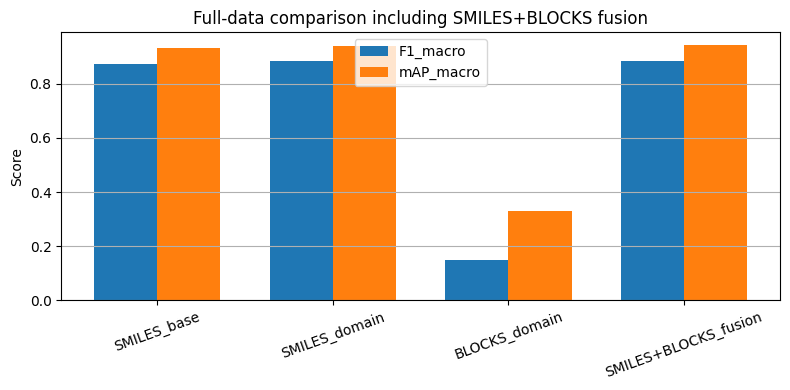

In [31]:
# ==== CELL 7: Compare SMILES+BLOCKS fusion vs previous models ====

# reuse your earlier `bench` if still in scope; otherwise re-create from `results`
fusion_row = {
    "model": "SMILES+BLOCKS_fusion",
    "f1_macro": test_metrics_fusion["f1_macro"],
    "mAP_macro": test_metrics_fusion["mAP_macro"],
    "f1_BRD4": test_metrics_fusion["f1_BRD4"],
    "f1_HSA": test_metrics_fusion["f1_HSA"],
    "f1_sEH": test_metrics_fusion["f1_sEH"],
    "roc_auc_BRD4": test_metrics_fusion["roc_auc_BRD4"],
    "roc_auc_HSA": test_metrics_fusion["roc_auc_HSA"],
    "roc_auc_sEH": test_metrics_fusion["roc_auc_sEH"],
}

bench_fusion = pd.concat([bench, pd.DataFrame([fusion_row])], ignore_index=True)
display(bench_fusion)

plt.figure(figsize=(8,4))
x = np.arange(len(bench_fusion))
f1s  = bench_fusion["f1_macro"].values
maps = bench_fusion["mAP_macro"].values

plt.bar(x - 0.18, f1s,  width=0.36, label="F1_macro")
plt.bar(x + 0.18, maps, width=0.36, label="mAP_macro")
plt.xticks(x, bench_fusion["model"].tolist(), rotation=20)
plt.ylabel("Score")
plt.title("Full-data comparison including SMILES+BLOCKS fusion")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()


Test block stats (filtered):


,block_id,BRD4,HSA,sEH,count_test,block_smiles
0,0,0.221359,0.526214,0.287379,515,O=C(Nc1cccc(Cl)c1C(=O)O)OCC1c2ccccc2-c2ccccc21
1,1,0.094787,0.271722,0.587678,633,O=C(O)C[C@H](Cc1ccc(Cl)c(Cl)c1)NC(=O)OCC1c2ccc...
2,2,0.244240,0.247312,0.485407,651,N#Cc1cccc(C[C@H](CC(=O)O)NC(=O)OCC2c3ccccc3-c3...
3,3,0.471316,0.222722,0.281215,889,O=C(O)CC(NC(=O)OCC1c2ccccc2-c2ccccc21)c1ccc(Br...
4,4,0.000203,0.000447,0.998335,24631,O=C(NC[C@H]1CC[C@H](C(=O)O)CC1)OCC1c2ccccc2-c2...


Block prediction stats:


,block_id,pred_BRD4,pred_HSA,pred_sEH
0,0,0.246959,0.643990,0.303817
1,1,0.123643,0.362810,0.615362
2,2,0.276795,0.330913,0.491189
3,3,0.479270,0.291043,0.305381
4,4,0.000446,0.001937,0.998885


Merged block-level eval (test):


,block_id,BRD4,HSA,sEH,count_test,block_smiles,pred_BRD4,pred_HSA,pred_sEH
0,0,0.221359,0.526214,0.287379,515,O=C(Nc1cccc(Cl)c1C(=O)O)OCC1c2ccccc2-c2ccccc21,0.246959,0.643990,0.303817
1,1,0.094787,0.271722,0.587678,633,O=C(O)C[C@H](Cc1ccc(Cl)c(Cl)c1)NC(=O)OCC1c2ccc...,0.123643,0.362810,0.615362
2,2,0.244240,0.247312,0.485407,651,N#Cc1cccc(C[C@H](CC(=O)O)NC(=O)OCC2c3ccccc3-c3...,0.276795,0.330913,0.491189
3,3,0.471316,0.222722,0.281215,889,O=C(O)CC(NC(=O)OCC1c2ccccc2-c2ccccc21)c1ccc(Br...,0.479270,0.291043,0.305381
4,4,0.000203,0.000447,0.998335,24631,O=C(NC[C@H]1CC[C@H](C(=O)O)CC1)OCC1c2ccccc2-c2...,0.000446,0.001937,0.998885


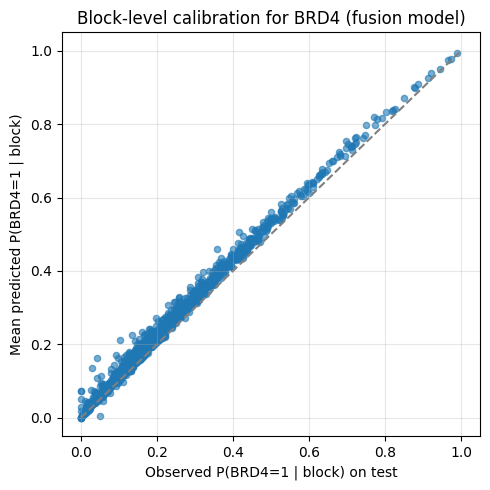

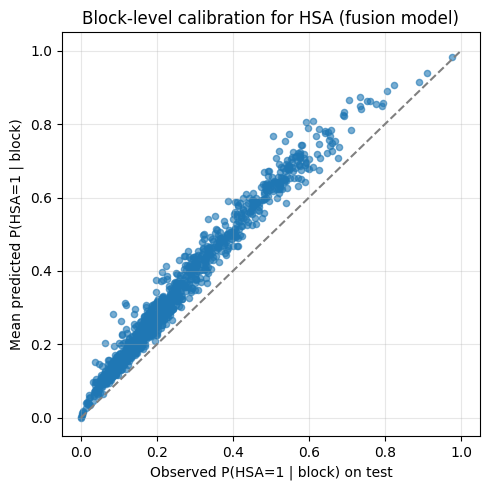

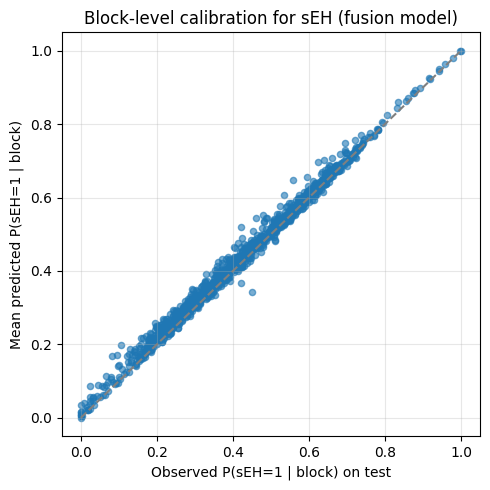

In [33]:
# ==== CELL B: Block-level predicted vs observed binding rates (test set) ====

device = CFG.device
fusion_model = fusion_model.to(device)
fusion_model.eval()

# 1) True block rates on TEST split
test_blocks = blocks_long[blocks_long["split"] == "test"].copy()

test_block_counts = (
    test_blocks.groupby("block_id")
    .size()
    .rename("count_test")
    .reset_index()
)

test_block_rates = (
    test_blocks.groupby("block_id")[CFG.label_cols]
    .mean()
    .reset_index()
)

test_block_stats = test_block_rates.merge(test_block_counts, on="block_id")
min_count_test = 10
test_block_stats = test_block_stats[test_block_stats["count_test"] >= min_count_test].copy()
test_block_stats["block_smiles"] = test_block_stats["block_id"].map(id2block)

print("Test block stats (filtered):")
display(test_block_stats.head())

# 2) Predicted probabilities per block from fusion model
@torch.no_grad()
def collect_block_preds(model, loader):
    block_pred_lists = {bid: [] for bid in test_block_stats["block_id"].values}
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        bb_ids = batch["bb_ids"].to(device)

        logits = model(input_ids, attn, bb_ids)
        probs = torch.sigmoid(logits).cpu().numpy()  # (B,3)

        bb_np = bb_ids.cpu().numpy()  # (B,3)
        for i in range(bb_np.shape[0]):
            for j in range(3):
                bid = bb_np[i, j]
                if bid in block_pred_lists:
                    block_pred_lists[bid].append(probs[i])
    # aggregate
    rows = []
    for bid, arr in block_pred_lists.items():
        if len(arr) == 0:
            continue
        arr = np.stack(arr, axis=0)  # (n_occ, 3)
        rows.append((bid, arr.mean(axis=0)))
    if not rows:
        return pd.DataFrame(columns=["block_id"] + [f"pred_{c}" for c in CFG.label_cols])
    block_ids, preds = zip(*rows)
    preds = np.stack(preds, axis=0)
    df = pd.DataFrame({"block_id": list(block_ids)})
    for i, c in enumerate(CFG.label_cols):
        df[f"pred_{c}"] = preds[:, i]
    return df

fusion_test_loader = make_fusion_loader(
    test_df_fusion, smiles_tokenizer, CFG.max_length_smiles, CFG.valid_batch_size, shuffle=False
)

block_pred_df = collect_block_preds(fusion_model, fusion_test_loader)
print("Block prediction stats:")
display(block_pred_df.head())

# 3) Merge true rates with predicted means
block_eval = test_block_stats.merge(block_pred_df, on="block_id", how="inner")
print("Merged block-level eval (test):")
display(block_eval.head())

# 4) Scatter plots: observed vs predicted per target
for target in CFG.label_cols:
    plt.figure(figsize=(5,5))
    x = block_eval[target]
    y = block_eval[f"pred_{target}"]
    plt.scatter(x, y, s=20, alpha=0.6)
    plt.plot([0,1],[0,1], linestyle="--", color="gray")
    plt.xlabel(f"Observed P({target}=1 | block) on test")
    plt.ylabel(f"Mean predicted P({target}=1 | block)")
    plt.title(f"Block-level calibration for {target} (fusion model)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


In [1]:
# ==== CELL D1: Collect raw outputs from fusion model & SMILES_domain on TEST ====

from sklearn.metrics import roc_curve, precision_recall_curve

device = CFG.device
fusion_model = fusion_model.to(device)
fusion_model.eval()
smiles_domain_model = smiles_domain_model.to(device)
smiles_domain_model.eval()

# 1) Fusion model outputs
@torch.no_grad()
def collect_fusion_outputs(model, loader):
    all_logits = []
    all_targets = []
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        bb_ids = batch["bb_ids"].to(device)
        targets = batch["labels"].to(device)

        logits = model(input_ids, attn, bb_ids)
        all_logits.append(logits.cpu())
        all_targets.append(targets.cpu())
    all_logits = torch.cat(all_logits, dim=0).numpy()
    all_targets = torch.cat(all_targets, dim=0).numpy()
    probs = 1.0 / (1.0 + np.exp(-all_logits))  # sigmoid
    return all_targets, probs

# reuse existing loader or recreate for safety
fusion_test_loader = make_fusion_loader(
    test_df_fusion, smiles_tokenizer, CFG.max_length_smiles, CFG.valid_batch_size, shuffle=False
)

y_true_fusion, y_prob_fusion = collect_fusion_outputs(fusion_model, fusion_test_loader)
print("Fusion outputs shape:", y_true_fusion.shape, y_prob_fusion.shape)


# 2) SMILES_domain outputs (SMILES-only model)
@torch.no_grad()
def collect_smiles_outputs(model, frame, text_col, tokenizer, max_length):
    ds = TextLabelDataset(frame, text_col, CFG.label_cols, tokenizer, max_length)
    loader = make_loader(ds, CFG.valid_batch_size, tokenizer, shuffle=False, pin_memory=False)

    all_logits = []
    all_targets = []
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        targets = batch["labels"].to(device)

        logits = model(input_ids, attn)
        all_logits.append(logits.cpu())
        all_targets.append(targets.cpu())
    all_logits = torch.cat(all_logits, dim=0).numpy()
    all_targets = torch.cat(all_targets, dim=0).numpy()
    probs = 1.0 / (1.0 + np.exp(-all_logits))
    return all_targets, probs

y_true_smiles, y_prob_smiles = collect_smiles_outputs(
    smiles_domain_model, test_df, "molecule_smiles", smiles_tokenizer, CFG.max_length_smiles
)
print("SMILES_domain outputs shape:", y_true_smiles.shape, y_prob_smiles.shape)

# they should align in order if splits are the same; to be safe we just treat them independently


NameError: name 'CFG' is not defined